In [ ]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt

import sklearn as sk
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    log_loss
) 


In [2]:
data= pd.read_csv('/home/rihabehml/GitHubProjects/ML/British-Airways-customers-buying-behavior/data/encoded_customer_booking.csv')
data.head()

,num_passengers,purchase_lead,length_of_stay,flight_hour,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,booking_complete,sales_channel_Internet,...,trip_type_RoundTrip,flight_day_Fri,flight_day_Mon,flight_day_Sat,flight_day_Sun,flight_day_Thu,flight_day_Tue,flight_day_Wed,route,booking_origin
0,2,262,19,7,1,0,0,5.52,0,1.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.052489
1,1,112,20,3,0,0,0,5.52,0,1.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.049639
2,2,243,22,17,1,1,0,5.52,0,1.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.101913
3,1,96,31,4,0,0,1,5.52,0,1.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.052489
4,2,68,22,15,1,0,1,5.52,0,1.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.095886


First, split data to test and train

In [27]:
print(data["booking_complete"].value_counts())
print(data["booking_complete"].value_counts(normalize=True) * 100)

booking_complete
0    42522
1     7478
Name: count, dtype: int64
booking_complete
0    85.044
1    14.956
Name: proportion, dtype: float64


In [4]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(data.drop('booking_complete', axis=1), data['booking_complete'], test_size=0.2, random_state=42)

### Model 1 : Logistic regression

In [28]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(class_weight="balanced")
lr_model.fit(x_train, y_train)

y_pred_lr = lr_model.predict(x_test)

/home/rihabehml/GitHubProjects/ML/British-Airways-customers-buying-behavior/.venv/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [32]:
print({
    "Accuracy" : accuracy_score(y_test,y_pred_lr),
    "Precision" : precision_score(y_test, y_pred_lr),
    "Recall" : recall_score(y_test,y_pred_lr),
    "F1 score" : f1_score(y_test,y_pred_lr)
    })


{'Accuracy': 0.7225, 'Precision': 0.3106171395144779, 'Recall': 0.7175675675675676, 'F1 score': 0.43355786895284754}


### Model 2 : RandomForest

In [52]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=100, random_state=42,class_weight="balanced")
rf_model.fit(x_train, y_train)

y_pred_rf = rf_model.predict(x_test)

In [53]:
rf_model.score(x_test, y_test)

0.857

In [54]:
print({
    "Accuracy" : accuracy_score(y_test,y_pred_rf),
    "Precision" : precision_score(y_test, y_pred_rf),
    "Recall" : recall_score(y_test,y_pred_rf),
    "F1 score" : f1_score(y_test,y_pred_rf)
    })

{'Accuracy': 0.857, 'Precision': 0.5880281690140845, 'Recall': 0.11283783783783784, 'F1 score': 0.1893424036281179}


In [61]:
from sklearn.metrics import precision_score, recall_score, f1_score

y_proba = rf_model.predict_proba(x_test)[:, 1]

for threshold in [0.5, 0.4, 0.3, 0.22,0.2,0.18,0.15, 0.1]:
    y_pred_threshold = (y_proba >= threshold).astype(int)

    print(
        f"Threshold: {threshold:.2f} | "
        f"Precision: {precision_score(y_test, y_pred_threshold):.3f} | "
        f"Recall: {recall_score(y_test, y_pred_threshold):.3f} | "
        f"F1: {f1_score(y_test, y_pred_threshold):.3f}"
    )

Threshold: 0.50 | Precision: 0.581 | Recall: 0.124 | F1: 0.204
Threshold: 0.40 | Precision: 0.500 | Recall: 0.257 | F1: 0.340
Threshold: 0.30 | Precision: 0.404 | Recall: 0.445 | F1: 0.423
Threshold: 0.22 | Precision: 0.348 | Recall: 0.627 | F1: 0.447
Threshold: 0.20 | Precision: 0.332 | Recall: 0.677 | F1: 0.446
Threshold: 0.18 | Precision: 0.320 | Recall: 0.718 | F1: 0.442
Threshold: 0.15 | Precision: 0.300 | Recall: 0.781 | F1: 0.433
Threshold: 0.10 | Precision: 0.253 | Recall: 0.857 | F1: 0.390


In [ ]:
# Predict probabilities
y_proba = rf_model.predict_proba(x_test)[:, 1]

# Apply chosen threshold
threshold = 0.22
y_pred = (y_proba >= threshold).astype(int)

#Evaluate the predictions
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.92      0.80      0.86      8520
           1       0.35      0.63      0.45      1480

    accuracy                           0.77     10000
   macro avg       0.64      0.71      0.65     10000
weighted avg       0.84      0.77      0.79     10000



In [63]:
from sklearn.metrics import average_precision_score

y_proba = rf_model.predict_proba(x_test)[:, 1]

pr_auc = average_precision_score(y_test, y_proba)

print("PR-AUC:", pr_auc)

PR-AUC: 0.40145579661863634


In [49]:
from sklearn.inspection import permutation_importance
importance = permutation_importance(
    rf_model,
    x_test,
    y_test,
    scoring="f1",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": x_test.columns,
    "Importance": importance.importances_mean,
    "Std": importance.importances_std
}).sort_values("Importance", ascending=False)

print(importance_df.round(4))


                   Feature  Importance     Std
20                   route      0.1430  0.0067
21          booking_origin      0.1119  0.0073
7          flight_duration      0.0861  0.0065
2           length_of_stay      0.0607  0.0060
1            purchase_lead      0.0362  0.0073
3              flight_hour      0.0287  0.0057
4      wants_extra_baggage      0.0286  0.0064
6    wants_in_flight_meals      0.0209  0.0062
5     wants_preferred_seat      0.0127  0.0069
0           num_passengers      0.0126  0.0071
8   sales_channel_Internet      0.0116  0.0025
9     sales_channel_Mobile      0.0098  0.0029
17          flight_day_Thu      0.0078  0.0037
19          flight_day_Wed      0.0076  0.0028
16          flight_day_Sun      0.0054  0.0019
18          flight_day_Tue      0.0054  0.0022
15          flight_day_Sat      0.0031  0.0031
13          flight_day_Fri      0.0026  0.0034
14          flight_day_Mon      0.0012  0.0041
12     trip_type_RoundTrip      0.0008  0.0007
11        tri

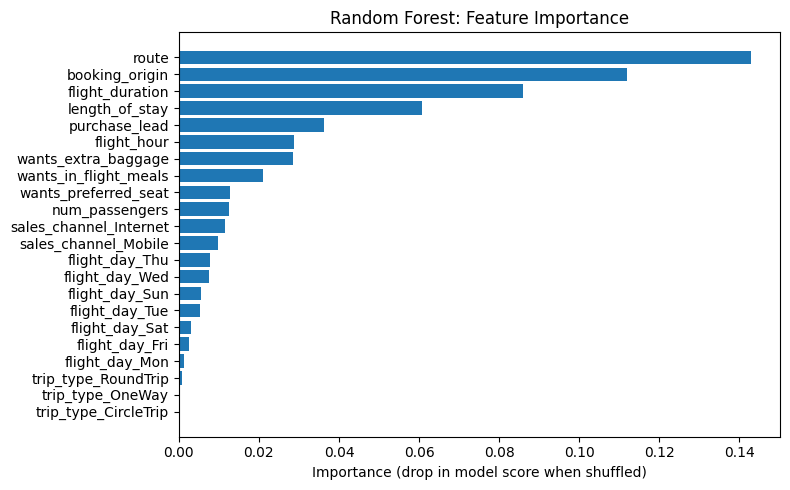

In [50]:
import matplotlib.pyplot as plt

plot_data = importance_df.sort_values("Importance")

plt.figure(figsize=(8, 5))
plt.barh(plot_data["Feature"], plot_data["Importance"])
plt.xlabel("Importance (drop in model score when shuffled)")
plt.title("Random Forest: Feature Importance")
plt.tight_layout()
plt.show()

In [64]:
#cross-validation
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(n_splits=7, shuffle=True, random_state=42)

scores = cross_val_score(
    rf_model,
    x_train,
    y_train,
    cv=cv,
    scoring="f1"
)

print("Mean CV f1-score:", scores.mean())


Mean CV f1-score: 0.15442866628684887
